In [1]:
import pandas as pd
import numpy as np
from scipy.optimize import root
from scipy.special import ndtr
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../Data/aggregation/BA_for_CG.csv')

In [3]:
def merton_spread(S, vol, B, T, r):
    pv = B * np.exp(-r * T)

    def equations(z):
        V, sigma_V = np.exp(z)
        d1 = (np.log(V / B) + (r + sigma_V**2 / 2) * T) / (sigma_V * np.sqrt(T))
        d2 = d1 - sigma_V * np.sqrt(T)
        return [(V * ndtr(d1) - pv * ndtr(d2)) / S - 1,
                sigma_V * V * ndtr(d1) / (vol * S) - 1]

    V0 = S + pv
    V, sigma_V = np.exp(root(equations, np.log([V0, vol * S / V0])).x)
    d1 = (np.log(V / B) + (r + sigma_V**2 / 2) * T) / (sigma_V * np.sqrt(T))
    d2 = d1 - sigma_V * np.sqrt(T)
    debt = V * ndtr(-d1) + pv * ndtr(d2)
    return -np.log(debt / pv) / T * 10000

In [4]:
maturity = pd.Timestamp("2038-02-15")
df["Date"] = pd.to_datetime(df["Date"])
df["T"] = (maturity - df["Date"]).dt.days / 365.25
df["B"] = (df["STD"] + df["LTD"]) / df["Shares"]

result = df[["Date", "Z"]].rename(columns={"Z": "Z_spread"})
for vol, name in [("IV", "IV"), ("sigma_garch_t", "GARCH")]:
    x = df.dropna(subset=["Close", "B", "T", "rf", vol])
    result[f"Merton_{name}"] = x.apply(
        lambda row: merton_spread(row["Close"], row[vol], row["B"], row["T"], row["rf"] / 100),
        axis=1
    )

result = result[result["Date"].between("2018-01-01", "2025-01-01", inclusive="neither")]
result

,Date,Z_spread,Merton_IV,Merton_GARCH
503,2018-01-02,109.249072,0.348368,0.000038
504,2018-01-03,107.415780,0.276773,0.000022
505,2018-01-04,109.310532,0.276724,0.000021
506,2018-01-05,99.885654,0.273329,0.125357
507,2018-01-08,106.192629,0.325940,0.054549
...,...,...,...,...
2259,2024-12-24,153.571425,69.431405,16.248108
2260,2024-12-26,154.236880,65.721219,12.784198
2261,2024-12-27,155.135377,63.474610,9.706209
2262,2024-12-30,146.711071,60.027431,14.650914


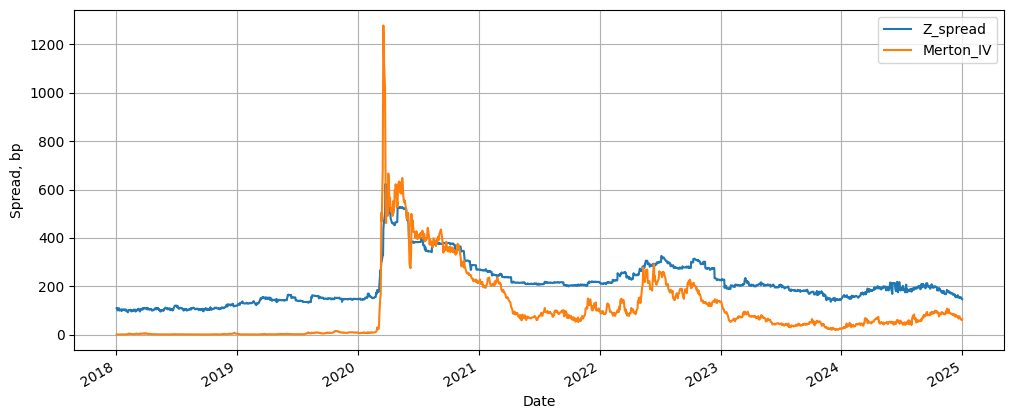

In [5]:
ax = result.plot(x="Date", y=["Z_spread", "Merton_IV"],
                 figsize=(12, 5), grid=True)
ax.set_ylabel("Spread, bp")
plt.show()

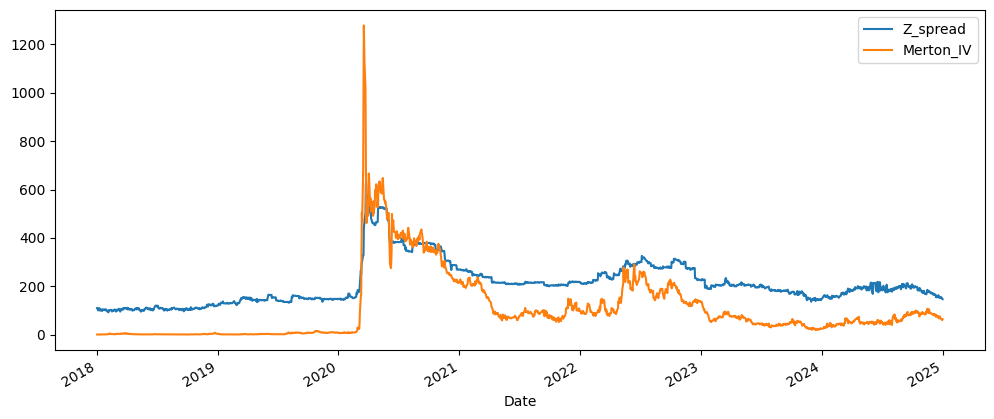

In [6]:
ax = result.plot(x="Date", y="Z_spread", figsize=(12, 5), grid=True)
result.plot(x="Date", y="Merton_IV", ax=ax, secondary_y=False)
plt.show()

In [8]:
result.to_csv('Merton.csv')